In [2]:
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt

df = pd.read_parquet("../data/features.parquet")
base = df["churned"].mean()
n_churn = df["churned"].sum()

def churn_by(df, cols):
    g = (df.groupby(cols, observed=True)["churned"]
           .agg(n="size", churn_rate="mean").reset_index())
    g["moe95"] = 1.96 * np.sqrt(g.churn_rate * (1 - g.churn_rate) / g.n)  # kasar
    g["lift"] = g.churn_rate / base
    g["share_cust"] = g.n / len(df)
    g["share_churners"] = g.n * g.churn_rate / n_churn
    g["small_n"] = g.n < 100
    return g.round(3)

print(f"baseline churn = {base:.3f}, total churner = {n_churn}")

baseline churn = 0.265, total churner = 1869


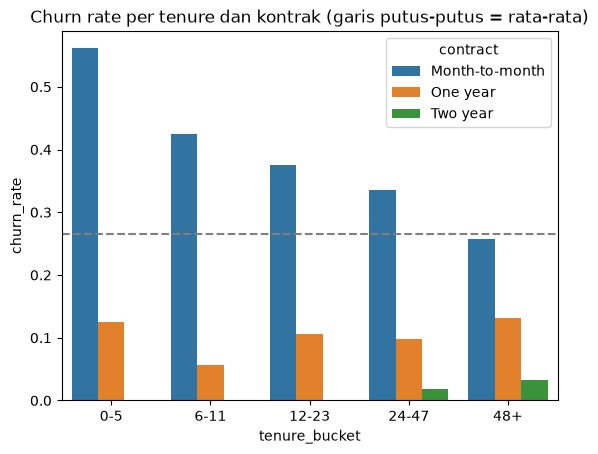

In [3]:
order = ["0-5", "6-11", "12-23", "24-47", "48+"]
g = churn_by(df, ["tenure_bucket", "contract"])
sns.barplot(data=g, x="tenure_bucket", y="churn_rate", hue="contract", order=order)
plt.axhline(base, ls="--", c="gray")
plt.title("Churn rate per tenure dan kontrak (garis putus-putus = rata-rata)")
plt.show()